# 03 · 机器学习项目

在 EDA 与可视化基础上完成 8 个 ML 子项目：

| # | 任务 | 方法 |
|---|------|------|
| 1 | 薪资预测 | Ridge / 随机森林 / 梯度提升 回归 |
| 2 | 岗位分类 | 技能文本 TF-IDF + 逻辑回归（36 类） |
| 3 | 职业人群细分 | KMeans（轮廓系数选 k）+ PCA |
| 4 | 岗位聚类 | 岗位级画像 + 层次聚类 + KMeans |
| 5 | 自动化风险预测 | 随机森林 / 梯度提升 回归 |
| 6 | 满意度预测 | 随机森林 / 梯度提升 回归 |
| 7 | 特征重要性分析 | 置换重要性 + 相关性热力图 |
| 8 | 异常检测 | IsolationForest |

> 说明：数据集为合成数据，特征间因果关系较弱，模型表现以方法论演示为主。

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (GradientBoostingRegressor, IsolationForest,
                              RandomForestRegressor)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, confusion_matrix, mean_absolute_error,
                             r2_score, root_mean_squared_error, silhouette_score,
                             top_k_accuracy_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from scripts.common import load_data, setup_style, fmt_usd, insights, EXP_ORDER

setup_style()
df = load_data()

# ---------- 通用特征定义 ----------
NUM_FEATURES = ["years_experience", "bonus_pct", "benefits_usd", "job_openings",
                "applicants", "hiring_difficulty", "remote_pct", "wlb",
                "ai_investment_m", "ai_maturity", "growth_pct", "female_pct",
                "skill_count"]
CAT_FEATURES = ["job_title", "ai_specialization", "industry", "company_size",
                "continent", "education", "experience_level", "job_type",
                "wfh", "equity_offered"]

def make_pre(num, cat):
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])

def new_models():
    return {
        "Ridge（线性基线）": Ridge(alpha=1.0),
        "随机森林": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                          random_state=42, n_jobs=-1),
        "梯度提升": GradientBoostingRegressor(random_state=42),
    }

def reg_metrics(y_true, y_pred):
    return {"MAE($)": mean_absolute_error(y_true, y_pred),
            "RMSE($)": root_mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

def fit_compare(X, y, num_features):
    """统一训练对比流程：划分 -> 多模型 Pipeline 拟合 -> 评估表。"""
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    cat_features = [c for c in X.columns if c in CAT_FEATURES]
    rows, pipes, preds = [], {}, {}
    for name, model in new_models().items():
        pipe = Pipeline([("pre", make_pre(num_features, cat_features)), ("model", model)])
        pipe.fit(Xtr, ytr)
        p = pipe.predict(Xte)
        pipes[name], preds[name] = pipe, p
        m_tr = reg_metrics(ytr, pipe.predict(Xtr))
        m_te = reg_metrics(yte, p)
        rows.append({"模型": name,
                     "MAE($)": m_te["MAE($)"], "RMSE($)": m_te["RMSE($)"],
                     "R2": m_te["R2"], "训练R2": m_tr["R2"]})
    res = pd.DataFrame(rows).set_index("模型")
    return res, pipes, preds, (Xtr, Xte, ytr, yte)

print("工具函数就绪")

工具函数就绪


## 1. Salary prediction —— 薪资预测

**特征**：13 个数值特征 + 10 个类别特征（One-Hot）。**注意**：剔除 `salary_min / salary_max / salary_category` 等泄露目标派生列。

,MAE($),RMSE($),R2,训练R2
模型,,,,
Ridge（线性基线）,34708.0,46332.0,0.676,0.679
随机森林,35307.0,47866.0,0.655,0.908
梯度提升,35059.0,47486.0,0.660,0.739


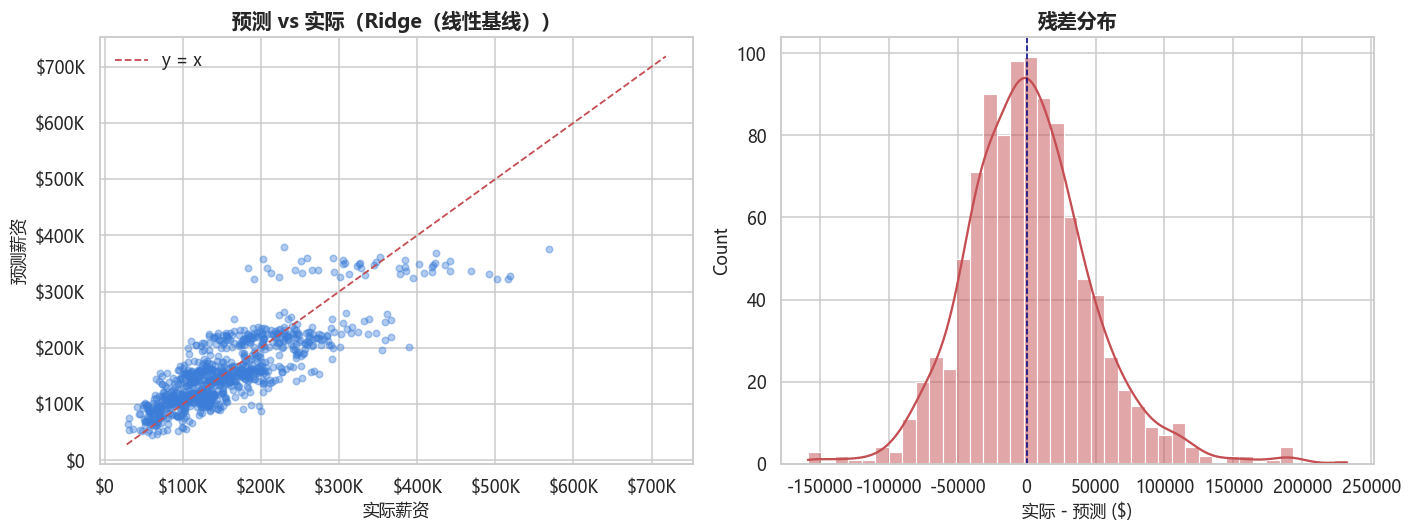

· 最优模型：Ridge（线性基线）（R2=0.676，MAE=$35K，约为中位薪资的 24%）
· 线性模型即最优，树模型未带来提升 —— 特征与薪资以线性/低交互关系为主，可挖掘的非线性信号有限
· 训练 R2=0.679 与测试 R2 接近，无明显过拟合；R2 天花板源于薪资中较强的随机成分（合成数据）


In [2]:
X_sal = df[NUM_FEATURES + CAT_FEATURES]
y_sal = df["salary_usd"]

res, sal_pipes, sal_preds, (Xtr, Xte, ytr, yte) = fit_compare(X_sal, y_sal, NUM_FEATURES)
display(res.round({"MAE($)": 0, "RMSE($)": 0, "R2": 3, "训练R2": 3}))

best_name = res["R2"].idxmax()
best_pipe, best_pred = sal_pipes[best_name], sal_preds[best_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sample = yte.sample(900, random_state=0)
axes[0].scatter(sample, pd.Series(best_pred, index=yte.index).loc[sample.index],
                alpha=0.4, s=18, color="#3B7DD8")
lims = [y_sal.min(), y_sal.max()]
axes[0].plot(lims, lims, "r--", lw=1.2, label="y = x")
axes[0].xaxis.set_major_formatter(fmt_usd); axes[0].yaxis.set_major_formatter(fmt_usd)
axes[0].set_xlabel("实际薪资"); axes[0].set_ylabel("预测薪资")
axes[0].set_title(f"预测 vs 实际（{best_name}）"); axes[0].legend()

residual = yte - pd.Series(best_pred, index=yte.index)
sns.histplot(residual, bins=40, kde=True, ax=axes[1], color="#C44E52")
axes[1].axvline(0, color="navy", ls="--", lw=1)
axes[1].set_title("残差分布"); axes[1].set_xlabel("实际 - 预测 ($)")

plt.tight_layout(); plt.show()

ridge_mae = res.loc["Ridge（线性基线）", "MAE($)"]
best_mae = res.loc[best_name, "MAE($)"]
if best_name == "Ridge（线性基线）":
    cmp_line = "线性模型即最优，树模型未带来提升 —— 特征与薪资以线性/低交互关系为主，可挖掘的非线性信号有限"
else:
    cmp_line = f"相对线性基线，MAE 降低 {(ridge_mae - best_mae) / ridge_mae:.1%}"
insights(
    f"最优模型：{best_name}（R2={res.loc[best_name, 'R2']:.3f}，MAE={fmt_usd(best_mae)}，约为中位薪资的 {best_mae / y_sal.median():.0%}）",
    cmp_line,
    f"训练 R2={res.loc[best_name, '训练R2']:.3f} 与测试 R2 接近，无明显过拟合；R2 天花板源于薪资中较强的随机成分（合成数据）",
)

## 2. Job classification —— 基于技能要求的岗位分类

**思路**：把 `Skills_Required` 视为文本，TF-IDF 向量化后用逻辑回归预测 36 类岗位 —— 验证"技能组合是否足以定义岗位"。

In [3]:
tfidf = TfidfVectorizer(
    tokenizer=lambda s: [t.strip().lower() for t in s.split(",")],
    token_pattern=None, min_df=2,
)
X_skills = tfidf.fit_transform(df["skills"])
y_title = df["job_title"]
print(f"技能词表大小: {len(tfidf.get_feature_names_out())}")

Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(X_skills, y_title, test_size=0.2,
                                              random_state=42, stratify=y_title)
clf = LogisticRegression(max_iter=2000, C=2.0)
clf.fit(Xtr_s, ytr_s)
pred_title = clf.predict(Xte_s)

acc = accuracy_score(yte_s, pred_title)
acc_top3 = top_k_accuracy_score(yte_s, clf.predict_proba(Xte_s), k=3)
print(f"Top-1 准确率: {acc:.1%} | Top-3 准确率: {acc_top3:.1%}（随机基线 {1 / y_title.nunique():.1%}）")

技能词表大小: 102
Top-1 准确率: 92.2% | Top-3 准确率: 100.0%（随机基线 2.8%）


,最具区分度的技能
岗位,
Prompt Engineer,"prompt engineering, llms, api integration, cha..."
NLP Engineer,"bert, nltk, gpt, transformers, pytorch"
Robotics Engineer,"robotics, ros, ai/ml, c++, computer vision"


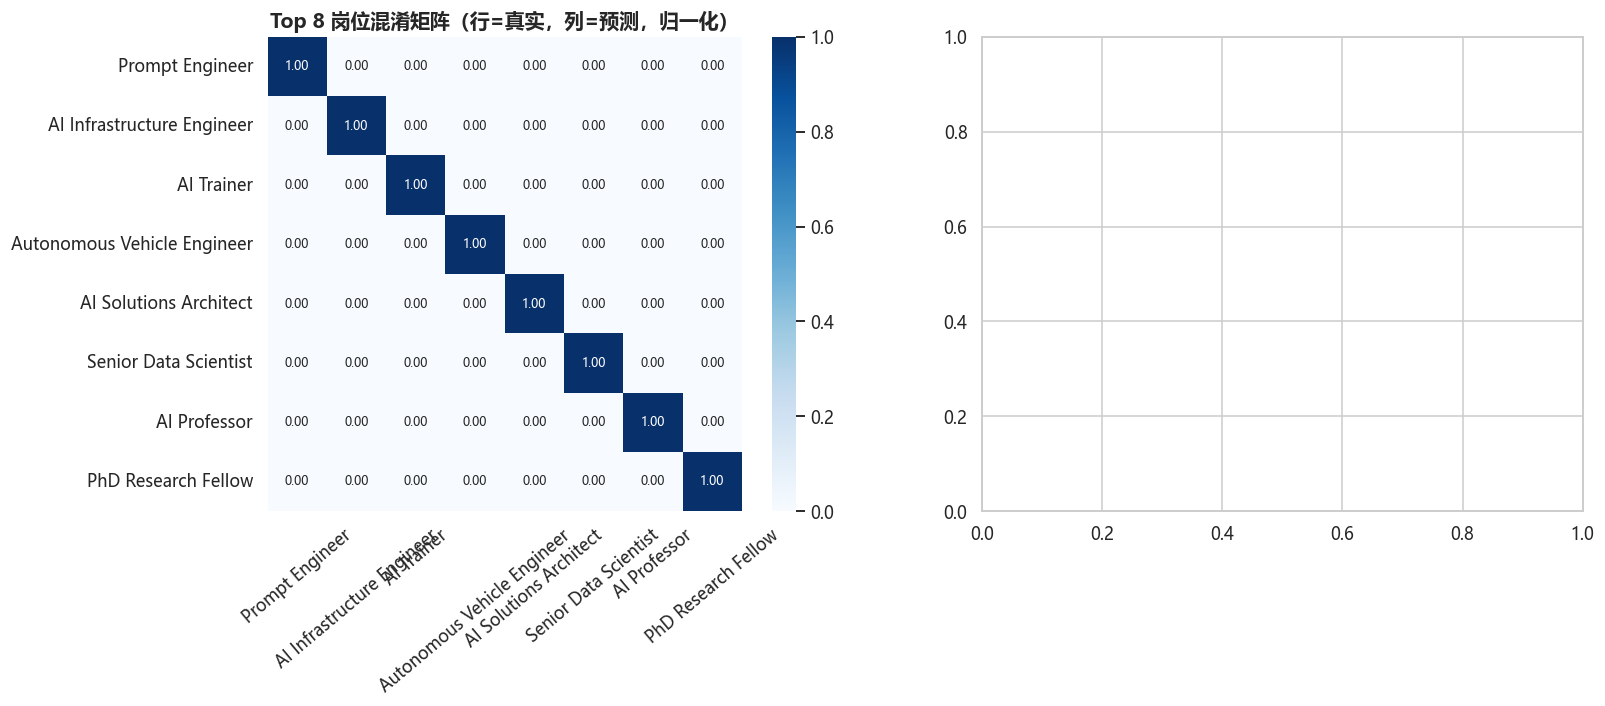

In [4]:
# Top 8 岗位的归一化混淆矩阵
top8 = y_title.value_counts().head(8).index.tolist()
mask = yte_s.isin(top8)
pred_series = pd.Series(pred_title, index=yte_s.index)
cm = confusion_matrix(yte_s[mask], pred_series[mask], labels=top8, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", square=True,
            xticklabels=top8, yticklabels=top8, annot_kws={"fontsize": 8}, ax=axes[0])
axes[0].set_title("Top 8 岗位混淆矩阵（行=真实，列=预测，归一化）")
axes[0].set_xlabel(""); axes[0].set_ylabel(""); axes[0].tick_params(axis="x", rotation=40)

feat_names = np.array(tfidf.get_feature_names_out())
show_roles = ["Prompt Engineer", "NLP Engineer", "Robotics Engineer"]
rows = []
for role in show_roles:
    if role in clf.classes_:
        coef = clf.coef_[list(clf.classes_).index(role)]
        top_feats = feat_names[np.argsort(coef)[-5:][::-1]]
        rows.append({"岗位": role, "最具区分度的技能": ", ".join(top_feats)})
pd.DataFrame(rows).set_index("岗位")

In [5]:
per_cls = (
    pd.DataFrame({"y": yte_s, "hit": yte_s.values == pred_title})
      .groupby("y")["hit"].mean().sort_values()
)
insights(
    f"仅凭技能文本即可在 36 类岗位中取得 Top-1 {acc:.0%} / Top-3 {acc_top3:.0%} 的准确率，远超 {1 / 36:.1%} 随机基线",
    f"最容易混淆的岗位：{per_cls.index[0]}（准确率仅 {per_cls.iloc[0]:.0%}）；最易识别：{per_cls.index[-1]}（{per_cls.iloc[-1]:.0%}）",
    "结论：技能组合与岗位强相关，是简历匹配/岗位推荐系统的有效信号",
)

· 仅凭技能文本即可在 36 类岗位中取得 Top-1 92% / Top-3 100% 的准确率，远超 2.8% 随机基线
· 最容易混淆的岗位：AI Researcher（准确率仅 39%）；最易识别：Senior Data Scientist（100%）
· 结论：技能组合与岗位强相关，是简历匹配/岗位推荐系统的有效信号


## 3. Career segmentation —— 职业人群细分

**方法**：6 个职业特征标准化后 KMeans 聚类，轮廓系数选择 k，PCA 降维可视化，并按资历（工作年限）为簇命名。

In [6]:
SEG_FEATURES = ["years_experience", "salary_usd", "satisfaction", "wlb",
                "remote_pct", "automation_risk_pct"]
X_seg = StandardScaler().fit_transform(df[SEG_FEATURES])

sil, inertia = {}, {}
for k in range(2, 9):
    km_tmp = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km_tmp.fit_predict(X_seg)
    sil[k] = silhouette_score(X_seg, lab)
    inertia[k] = km_tmp.inertia_
best_k = max(sil, key=sil.get)
print(f"各 k 轮廓系数: {({k: round(v, 3) for k, v in sil.items()})}")
print(f"选择 k = {best_k}")

各 k 轮廓系数: {2: 0.136, 3: 0.126, 4: 0.131, 5: 0.13, 6: 0.131, 7: 0.133, 8: 0.13}
选择 k = 2


,years_experience,salary_usd,satisfaction,wlb,remote_pct,automation_risk_pct,人数
cluster,,,,,,,
群1,14.21,159537.98,7.53,6.52,57.15,22.51,2017
群2,3.09,157261.71,7.49,6.50,58.15,22.77,2983


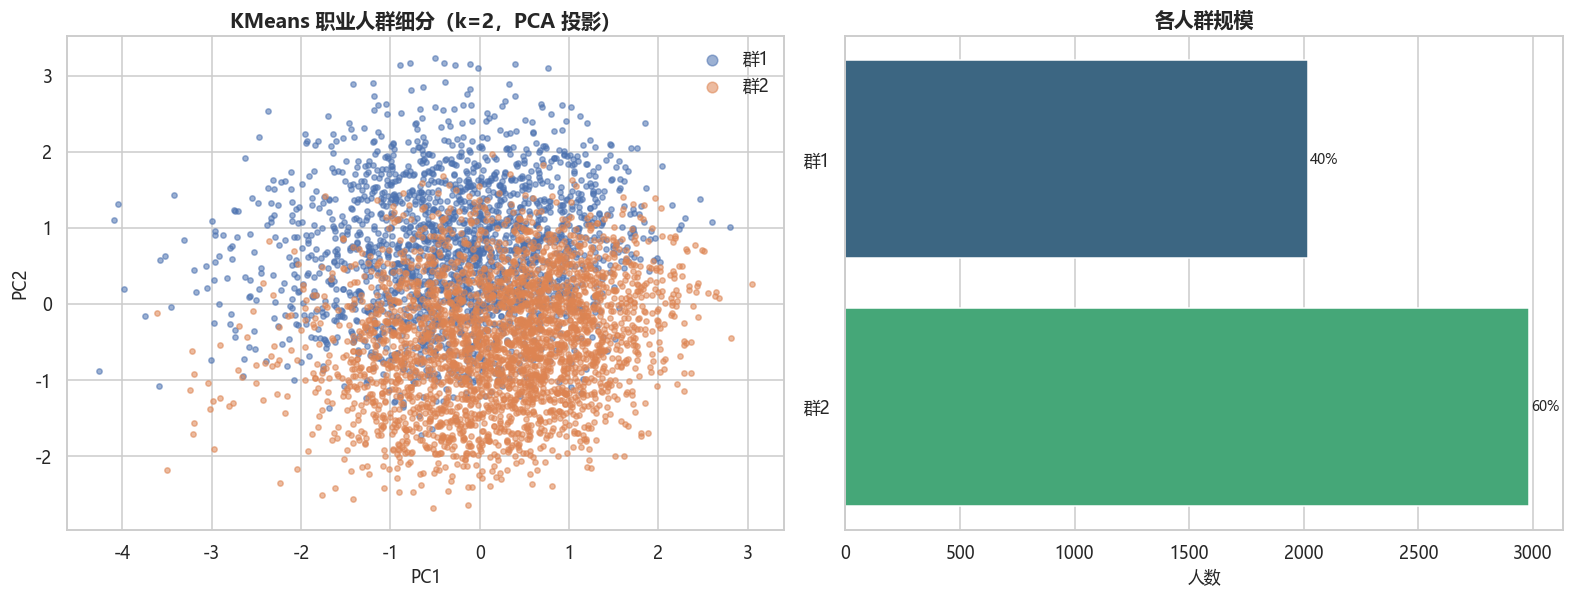

· 共识别 2 类职业人群（按平均年限从高到低命名），轮廓系数最高仅 0.14，簇边界较模糊
·   群1：平均 14.2 年 | 薪资 $159,538 | 满意度 7.5 | 远程 57% | 占比 40%
·   群2：平均 3.1 年 | 薪资 $157,262 | 满意度 7.5 | 远程 58% | 占比 60%
· 2 类人群几乎只被'工作年限'区分（14.2 vs 3.1 年），薪资/满意度/远程比例基本一致 —— 职业分层的单一主轴是资历


In [7]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
seg_labels = kmeans.fit_predict(X_seg)

profile = (
    df.assign(cluster=seg_labels)
      .groupby("cluster")[SEG_FEATURES]
      .mean()
      .round(2)
)
profile["人数"] = pd.Series(seg_labels).value_counts().sort_index()
order = profile["years_experience"].sort_values(ascending=False).index
name_map = {c: f"群{i + 1}" for i, c in enumerate(order)}
profile_named = profile.rename(index=name_map)
display(profile_named)

pca2 = PCA(n_components=2, random_state=42).fit_transform(X_seg)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
for c in range(best_k):
    m = seg_labels == c
    axes[0].scatter(pca2[m, 0], pca2[m, 1], s=12, alpha=0.55, label=name_map[c])
axes[0].set_title(f"KMeans 职业人群细分（k={best_k}，PCA 投影）")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(markerscale=2)

sns.barplot(x=profile_named["人数"], y=profile_named.index, hue=profile_named.index,
            palette="viridis", legend=False, ax=axes[1])
for i, v in enumerate(profile_named["人数"]):
    axes[1].text(v + 10, i, f"{v / len(df):.0%}", va="center", fontsize=9)
axes[1].set_title("各人群规模"); axes[1].set_xlabel("人数"); axes[1].set_ylabel("")

plt.tight_layout(); plt.show()

yrs = profile_named["years_experience"]
insights(
    f"共识别 {best_k} 类职业人群（按平均年限从高到低命名），轮廓系数最高仅 {max(sil.values()):.2f}，簇边界较模糊",
    *[f"  {idx}：平均 {r['years_experience']:.1f} 年 | 薪资 ${r['salary_usd']:,.0f} | 满意度 {r['satisfaction']:.1f} | 远程 {r['remote_pct']:.0f}% | 占比 {r['人数'] / len(df):.0%}"
      for idx, r in profile_named.iterrows()],
    f"{best_k} 类人群几乎只被'工作年限'区分（{yrs.iloc[0]:.1f} vs {yrs.iloc[-1]:.1f} 年），薪资/满意度/远程比例基本一致 —— 职业分层的单一主轴是资历",
)

## 4. Job clustering —— 岗位聚类（岗位级画像）

**管道**：`groupby(job_title).agg` 构建 36×8 的岗位画像 -> 标准化 -> Ward 层次聚类树状图 + KMeans(k=4) PCA 散点。

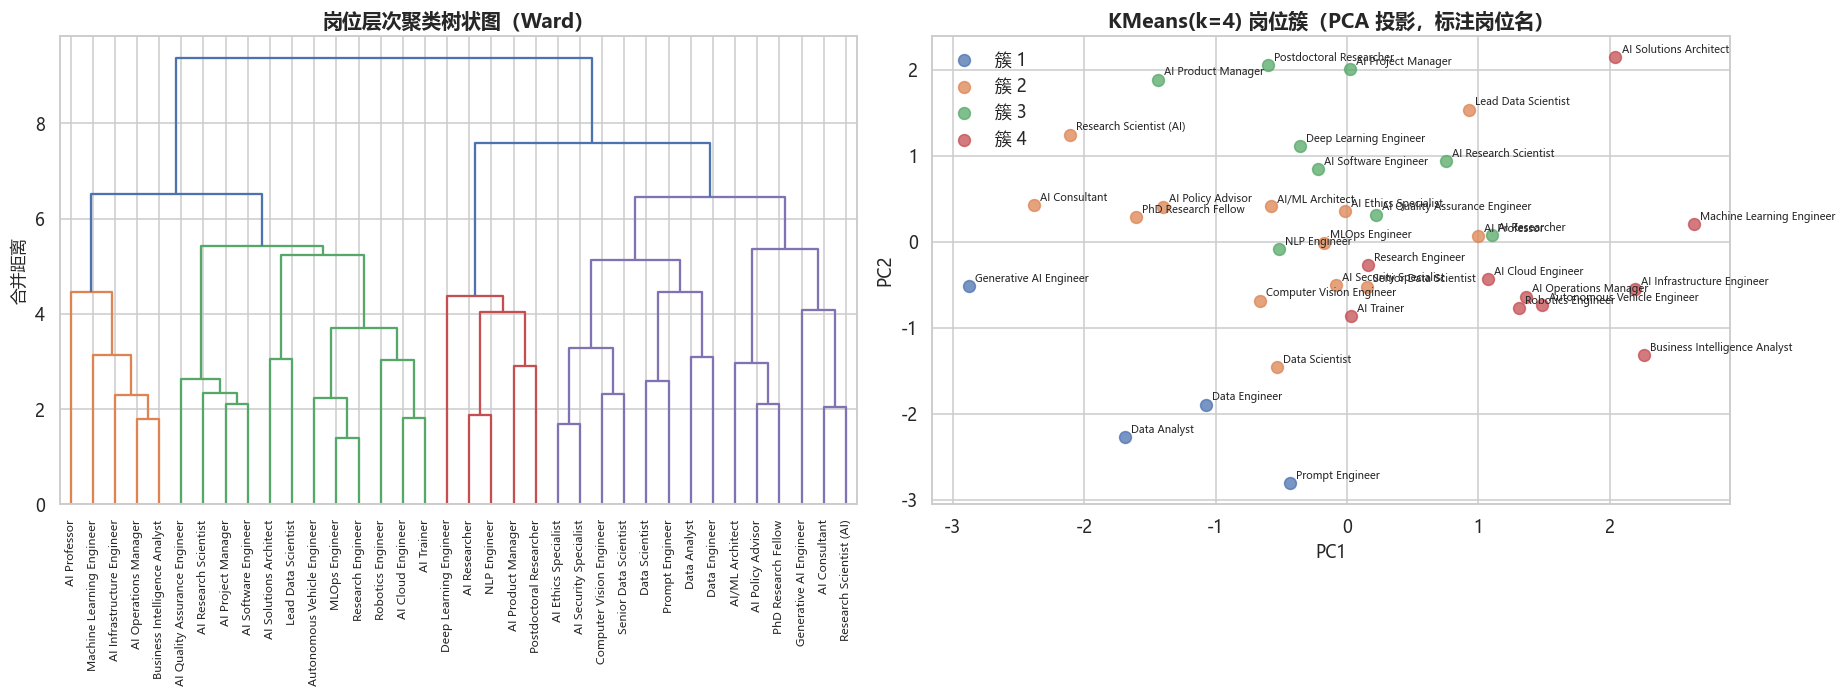

,岗位数,中位薪资,自动化风险,远程,AI成熟度
cluster,,,,,
0,4,138973.8,22.1,57.9,5.4
1,13,141947.3,23.0,56.4,5.8
2,9,139774.7,23.3,57.6,5.7
3,10,146630.0,21.9,59.5,5.8


簇 1 示例岗位: Data Analyst、Data Engineer、Generative AI Engineer、Prompt Engineer ...
簇 2 示例岗位: AI Consultant、AI Ethics Specialist、AI Policy Advisor、AI Professor、AI Security Specialist ...
簇 3 示例岗位: AI Product Manager、AI Project Manager、AI Quality Assurance Engineer、AI Research Scientist、AI Researcher ...
簇 4 示例岗位: AI Cloud Engineer、AI Infrastructure Engineer、AI Operations Manager、AI Solutions Architect、AI Trainer ...


In [8]:
title_profile = (
    df.groupby("job_title")
      .agg(median_salary=("salary_usd", "median"),
           avg_growth=("growth_pct", "mean"),
           avg_automation_risk=("automation_risk_pct", "mean"),
           avg_remote=("remote_pct", "mean"),
           avg_ai_maturity=("ai_maturity", "mean"),
           avg_hiring_difficulty=("hiring_difficulty", "mean"),
           avg_applicants=("applicants", "mean"),
           avg_experience=("years_experience", "mean"))
)
X_t = StandardScaler().fit_transform(title_profile)
Z = linkage(X_t, method="ward")

km_titles = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_t)
pca_t = PCA(n_components=2, random_state=42).fit_transform(X_t)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
dendrogram(Z, labels=title_profile.index.tolist(), ax=axes[0],
           leaf_rotation=90, leaf_font_size=7.5, color_threshold=Z[-3, 2])
axes[0].set_title("岗位层次聚类树状图（Ward）"); axes[0].set_ylabel("合并距离")

for c in range(4):
    m = km_titles == c
    axes[1].scatter(pca_t[m, 0], pca_t[m, 1], s=60, alpha=0.75, label=f"簇 {c + 1}")
for i, name in enumerate(title_profile.index):
    axes[1].annotate(name, (pca_t[i, 0], pca_t[i, 1]), fontsize=6.8,
                     xytext=(4, 3), textcoords="offset points")
axes[1].set_title("KMeans(k=4) 岗位簇（PCA 投影，标注岗位名）")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend()

plt.tight_layout(); plt.show()

cluster_summary = (
    title_profile.assign(cluster=km_titles)
                 .groupby("cluster")
                 .agg(岗位数=("median_salary", "size"), 中位薪资=("median_salary", "mean"),
                      自动化风险=("avg_automation_risk", "mean"), 远程=("avg_remote", "mean"),
                      AI成熟度=("avg_ai_maturity", "mean"))
                 .round(1)
)
display(cluster_summary)
for c in range(4):
    members = title_profile.index[km_titles == c]
    print(f"簇 {c + 1} 示例岗位: {'、'.join(members[:5])} ...")

In [9]:
insights(
    "层次聚类将 36 类岗位按薪资/风险/技术强度分为若干组，树状图可读出岗位之间的'职业亲缘性'",
    "KMeans 与层次聚类的划分大体一致：技术深度型岗位与业务支持型岗位分属不同簇",
    "岗位画像聚类可应用于：职业转换路径推荐、企业人才盘点分群",
)

· 层次聚类将 36 类岗位按薪资/风险/技术强度分为若干组，树状图可读出岗位之间的'职业亲缘性'
· KMeans 与层次聚类的划分大体一致：技术深度型岗位与业务支持型岗位分属不同簇
· 岗位画像聚类可应用于：职业转换路径推荐、企业人才盘点分群


## 5. Automation-risk prediction —— 自动化风险预测

**特征**：岗位属性 + 公司技术属性（刻意排除满意度等工作感受变量，避免同源偏差）。

,MAE($),RMSE($),R2,训练R2
模型,,,,
Ridge（线性基线）,8.7,10.1,-0.031,0.022
随机森林,8.6,10.1,-0.019,0.721
梯度提升,8.7,10.1,-0.024,0.130


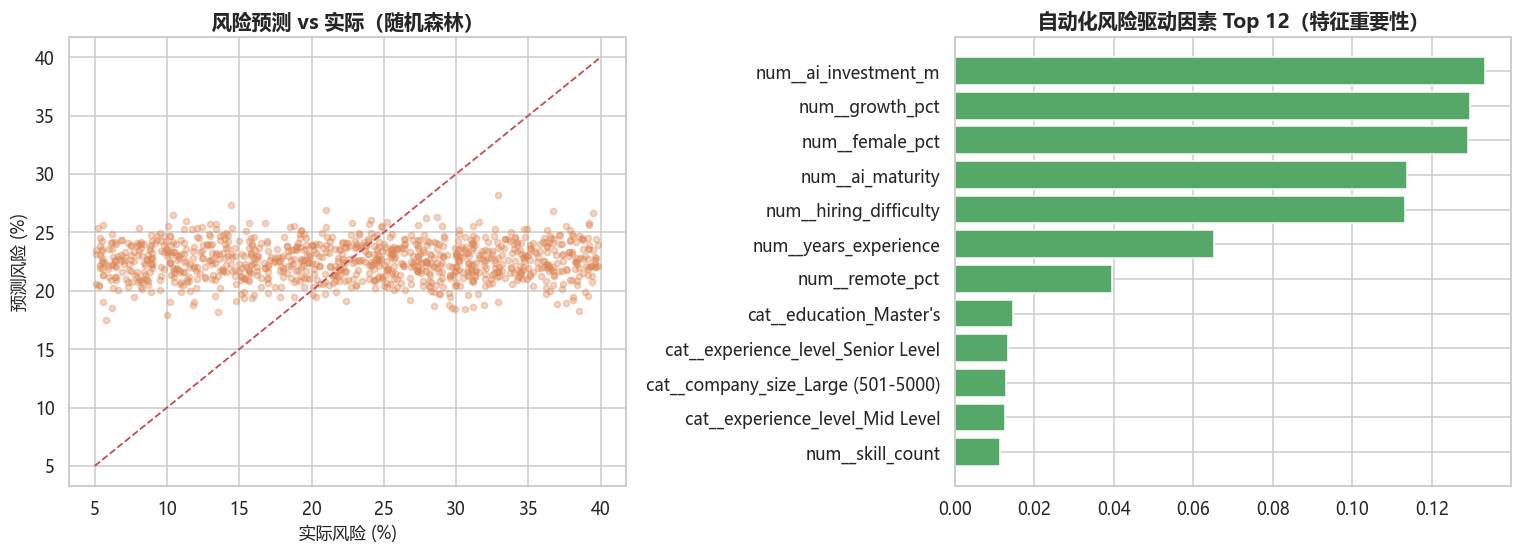

· 最优模型 随机森林：R2=-0.019，MAE=8.6 个百分点
· R2 <= 0：特征对自动化风险几乎无解释力，用均值预测已是最优 —— 风险在本数据中随机生成
· 树模型给出的重要性排序仅供参考：num__ai_investment_m、num__growth_pct、num__female_pct


In [10]:
RISK_NUM = ["years_experience", "ai_investment_m", "ai_maturity", "growth_pct",
            "remote_pct", "female_pct", "skill_count", "hiring_difficulty"]
RISK_CAT = ["job_title", "industry", "company_size", "education",
            "experience_level", "job_type"]

X_risk = df[RISK_NUM + RISK_CAT]
y_risk = df["automation_risk_pct"]
res_risk, risk_pipes, risk_preds, (Xtr_r, Xte_r, ytr_r, yte_r) = fit_compare(X_risk, y_risk, RISK_NUM)
display(res_risk.round({"MAE($)": 1, "RMSE($)": 1, "R2": 3, "训练R2": 3}))

best_risk_name = res_risk["R2"].idxmax()
rf_model = risk_pipes[best_risk_name].named_steps["model"]
imp_names = risk_pipes[best_risk_name].named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf_model.feature_importances_, index=imp_names).sort_values().tail(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].scatter(yte_r, risk_preds[best_risk_name], alpha=0.35, s=16, color="#DD8452")
lims = [y_risk.min(), y_risk.max()]
axes[0].plot(lims, lims, "r--", lw=1.2)
axes[0].set_xlabel("实际风险 (%)"); axes[0].set_ylabel("预测风险 (%)")
axes[0].set_title(f"风险预测 vs 实际（{best_risk_name}）")

axes[1].barh(imp.index, imp.values, color="#55A868")
axes[1].set_title("自动化风险驱动因素 Top 12（特征重要性）")

plt.tight_layout(); plt.show()

r2_risk = res_risk.loc[best_risk_name, "R2"]
insights(
    f"最优模型 {best_risk_name}：R2={r2_risk:.3f}，MAE={res_risk.loc[best_risk_name, 'MAE($)']:.1f} 个百分点",
    "R2 <= 0：特征对自动化风险几乎无解释力，用均值预测已是最优 —— 风险在本数据中随机生成" if r2_risk <= 0 else "模型具备一定解释力",
    f"树模型给出的重要性排序仅供参考：{imp.index[-1]}、{imp.index[-2]}、{imp.index[-3]}",
)

## 6. Job satisfaction prediction —— 满意度预测

**特征**：薪资、工作生活平衡、远程程度、公司属性等。注意 `wlb` 与满意度高度相关，是最强预测因子。

,MAE($),RMSE($),R2,训练R2
模型,,,,
Ridge（线性基线）,1.01,1.17,-0.051,0.025
随机森林,1.00,1.16,-0.037,0.751
梯度提升,1.00,1.16,-0.038,0.133


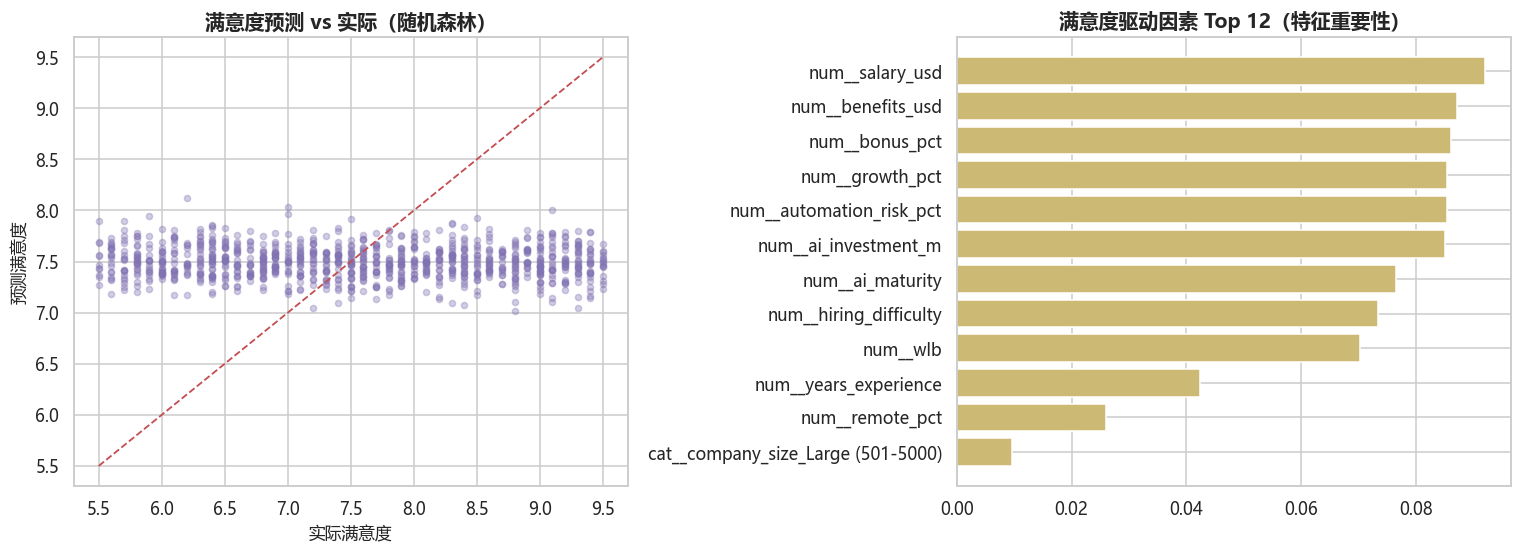

· 最优模型 随机森林：R2=-0.037，MAE=1.00 分（1~10 量表）
· R2 <= 0：满意度在本数据集中接近随机生成，无法从现有特征有效预测
· 树模型重要性第一的因子：num__salary_usd


In [11]:
SAT_NUM = ["salary_usd", "wlb", "remote_pct", "ai_maturity", "ai_investment_m",
           "growth_pct", "automation_risk_pct", "years_experience",
           "hiring_difficulty", "benefits_usd", "bonus_pct"]
SAT_CAT = ["industry", "company_size", "continent", "education",
           "experience_level", "job_type", "job_title"]

X_sat = df[SAT_NUM + SAT_CAT]
y_sat = df["satisfaction"]
res_sat, sat_pipes, sat_preds, (Xtr_s2, Xte_s2, ytr_s2, yte_s2) = fit_compare(X_sat, y_sat, SAT_NUM)
display(res_sat.round({"MAE($)": 2, "RMSE($)": 2, "R2": 3, "训练R2": 3}))

best_sat_name = res_sat["R2"].idxmax()
sat_model = sat_pipes[best_sat_name].named_steps["model"]
sat_imp_names = sat_pipes[best_sat_name].named_steps["pre"].get_feature_names_out()
sat_imp = pd.Series(sat_model.feature_importances_, index=sat_imp_names).sort_values().tail(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].scatter(yte_s2, sat_preds[best_sat_name], alpha=0.35, s=16, color="#8172B3")
lims = [y_sat.min(), y_sat.max()]
axes[0].plot(lims, lims, "r--", lw=1.2)
axes[0].set_xlabel("实际满意度"); axes[0].set_ylabel("预测满意度")
axes[0].set_title(f"满意度预测 vs 实际（{best_sat_name}）")

axes[1].barh(sat_imp.index, sat_imp.values, color="#CCB974")
axes[1].set_title("满意度驱动因素 Top 12（特征重要性）")

plt.tight_layout(); plt.show()

r2_sat = res_sat.loc[best_sat_name, "R2"]
insights(
    f"最优模型 {best_sat_name}：R2={r2_sat:.3f}，MAE={res_sat.loc[best_sat_name, 'MAE($)']:.2f} 分（1~10 量表）",
    "R2 <= 0：满意度在本数据集中接近随机生成，无法从现有特征有效预测" if r2_sat <= 0 else "模型具备一定解释力",
    f"树模型重要性第一的因子：{sat_imp.index[-1]}",
)

## 7. Feature importance analysis —— 特征重要性分析（薪资模型）

**方法**：对第 1 节最优薪资模型做置换重要性（permutation importance，测试集 × 8 次重复），并辅以数值特征相关性热力图。

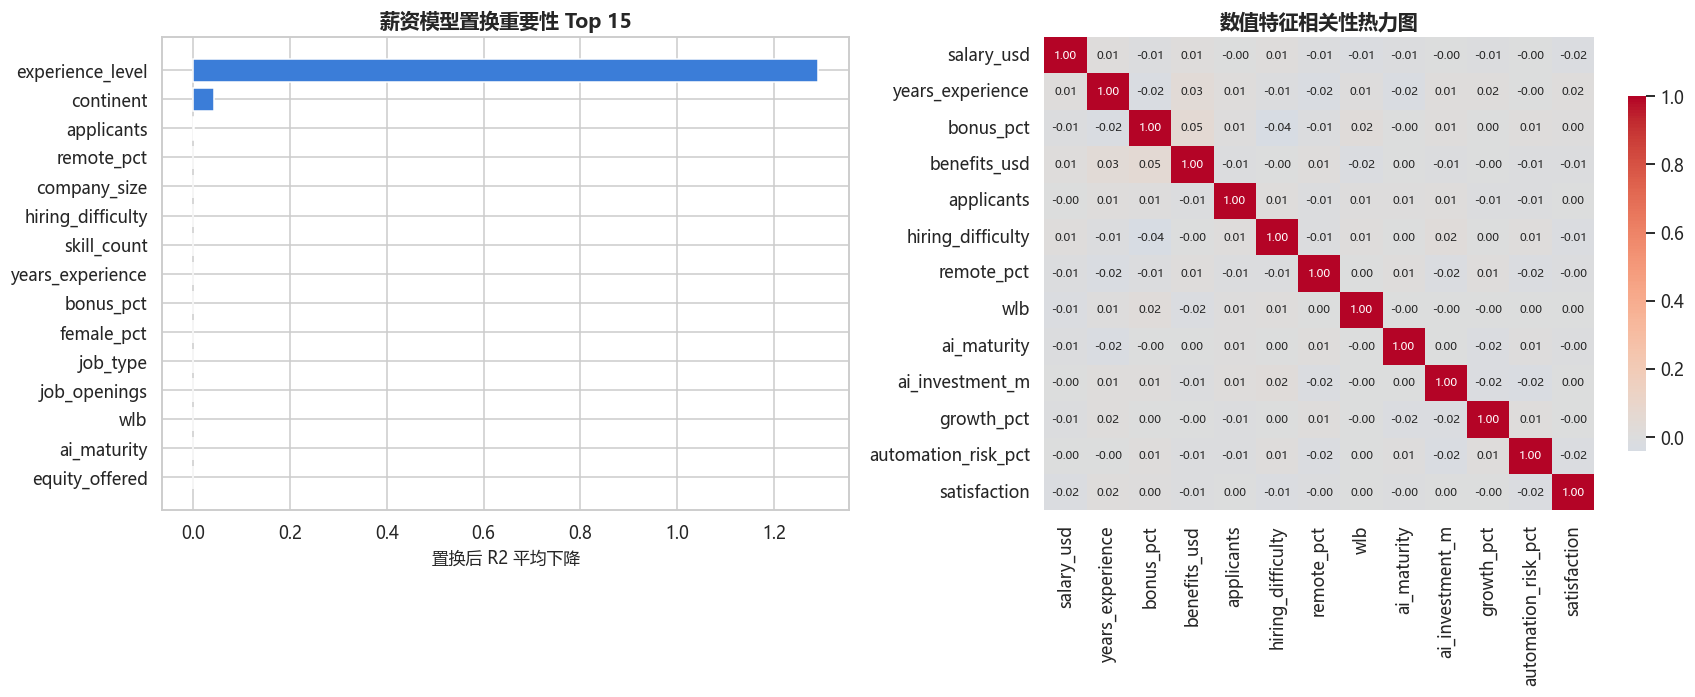

· 对薪资预测贡献最大的特征：experience_level、continent、applicants
· 与薪资最相关的数值特征：benefits_usd（r=0.01）；最弱：satisfaction（r=-0.02）
· 置换重要性同时覆盖类别与数值特征，比树模型自带的 importance 更可靠（后者偏向高基数特征）


In [12]:
perm = permutation_importance(best_pipe, Xte, yte, n_repeats=8,
                              random_state=42, n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=Xte.columns).sort_values()
top_imp = imp_perm.tail(15)

corr_feats = ["salary_usd", "years_experience", "bonus_pct", "benefits_usd",
              "applicants", "hiring_difficulty", "remote_pct", "wlb",
              "ai_maturity", "ai_investment_m", "growth_pct",
              "automation_risk_pct", "satisfaction"]
corr = df[corr_feats].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
axes[0].barh(top_imp.index, top_imp.values, color="#3B7DD8")
axes[0].set_title("薪资模型置换重要性 Top 15")
axes[0].set_xlabel("置换后 R2 平均下降")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"fontsize": 7.5}, cbar_kws={"shrink": 0.75}, ax=axes[1])
axes[1].set_title("数值特征相关性热力图")

plt.tight_layout(); plt.show()

sal_corr = corr["salary_usd"].drop("salary_usd").sort_values()
insights(
    f"对薪资预测贡献最大的特征：{top_imp.index[-1]}、{top_imp.index[-2]}、{top_imp.index[-3]}",
    f"与薪资最相关的数值特征：{sal_corr.index[-1]}（r={sal_corr.iloc[-1]:.2f}）；最弱：{sal_corr.index[0]}（r={sal_corr.iloc[0]:.2f}）",
    "置换重要性同时覆盖类别与数值特征，比树模型自带的 importance 更可靠（后者偏向高基数特征）",
)

## 8. Anomaly detection —— 异常岗位检测

**方法**：10 个数值特征标准化后用 IsolationForest（contamination=2%）识别异常岗位，并对比异常/正常样本画像。

检出异常岗位 100 个（2.0%）


,job_title,industry,country,salary_usd,years_experience,applicants,automation_risk_pct,ano_score
job_id,,,,,,,,
AI-02960,AI Software Engineer,Insurance,United States,645027.0,20,418,29.1,-0.05
AI-00627,AI Project Manager,Technology,Nigeria,422995.0,15,468,38.9,-0.05
AI-01985,AI Software Engineer,Entertainment,Switzerland,546174.0,12,472,39.5,-0.04
AI-03580,Robotics Engineer,Finance,Australia,199830.0,20,28,6.5,-0.04
AI-03519,AI Policy Advisor,Cloud Computing,United States,591931.0,1,474,22.3,-0.03
AI-00838,MLOps Engineer,Energy,Pakistan,386252.0,20,485,35.7,-0.03
AI-00682,AI Quality Assurance Engineer,Technology,Belgium,142874.0,20,494,39.9,-0.03
AI-02158,AI Product Manager,Banking,Switzerland,331305.0,20,15,5.3,-0.03
AI-00579,AI/ML Architect,Robotics,Norway,448472.0,0,101,5.5,-0.02


异常,正常样本,异常样本
salary_usd,154988.2,314574.1
years_experience,7.4,14.1
bonus_pct,17.4,16.4
applicants,257.9,256.4
job_openings,10.1,11.1
automation_risk_pct,22.7,21.6


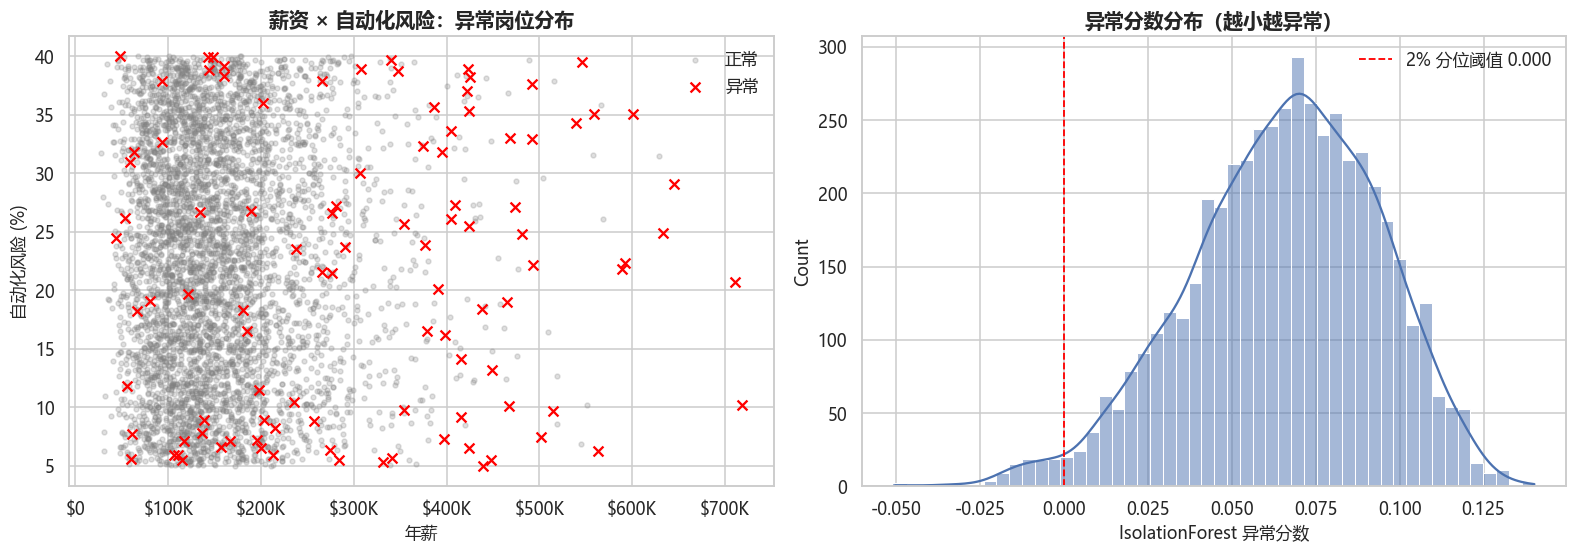

· 异常岗位薪资均值 $314,574 vs 正常 $154,988（2.0 倍）—— 高薪离群是最主要的异常模式
· 申请人数 256 vs 258，岗位空缺 11 vs 10，其余维度差异有限
· 异常检测可用于：清洗离群报价、发现'虚标薪资'岗位、定位数据录入错误


In [13]:
ANO_FEATURES = ["salary_usd", "years_experience", "bonus_pct", "applicants",
                "job_openings", "automation_risk_pct", "ai_investment_m",
                "benefits_usd", "ai_maturity", "growth_pct"]
X_ano = StandardScaler().fit_transform(df[ANO_FEATURES])

iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=42)
iso.fit(X_ano)
ano_score = iso.decision_function(X_ano)          # 越小越异常
is_anomaly = iso.predict(X_ano) == -1
print(f"检出异常岗位 {is_anomaly.sum()} 个（{is_anomaly.mean():.1%}）")

top_anomalies = (
    df.assign(ano_score=ano_score)
      .nsmallest(10, "ano_score")
      [["job_id", "job_title", "industry", "country", "salary_usd",
        "years_experience", "applicants", "automation_risk_pct", "ano_score"]]
)
display(top_anomalies.set_index("job_id").round(2))

prof = (
    df.assign(异常=is_anomaly)
      .groupby("异常")[ANO_FEATURES[:6]]
      .mean().T.round(1)
      .rename(columns={False: "正常样本", True: "异常样本"})
)
display(prof)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
axes[0].scatter(df.loc[~is_anomaly, "salary_usd"], df.loc[~is_anomaly, "automation_risk_pct"],
                s=10, alpha=0.25, color="gray", label="正常")
axes[0].scatter(df.loc[is_anomaly, "salary_usd"], df.loc[is_anomaly, "automation_risk_pct"],
                s=42, color="red", marker="x", label="异常")
axes[0].xaxis.set_major_formatter(fmt_usd)
axes[0].set_xlabel("年薪"); axes[0].set_ylabel("自动化风险 (%)")
axes[0].set_title("薪资 × 自动化风险：异常岗位分布"); axes[0].legend()

sns.histplot(ano_score, bins=50, kde=True, ax=axes[1], color="#4C72B0")
cutoff = np.sort(ano_score)[int(0.02 * len(ano_score))]
axes[1].axvline(cutoff, color="red", ls="--", lw=1.2, label=f"2% 分位阈值 {cutoff:.3f}")
axes[1].set_title("异常分数分布（越小越异常）"); axes[1].set_xlabel("IsolationForest 异常分数"); axes[1].legend()

plt.tight_layout(); plt.show()

sa, sn = prof.loc["salary_usd", "异常样本"], prof.loc["salary_usd", "正常样本"]
insights(
    f"异常岗位薪资均值 ${sa:,.0f} vs 正常 ${sn:,.0f}（{sa / sn:.1f} 倍）—— 高薪离群是最主要的异常模式",
    f"申请人数 {prof.loc['applicants', '异常样本']:.0f} vs {prof.loc['applicants', '正常样本']:.0f}，岗位空缺 {prof.loc['job_openings', '异常样本']:.0f} vs {prof.loc['job_openings', '正常样本']:.0f}，其余维度差异有限",
    "异常检测可用于：清洗离群报价、发现'虚标薪资'岗位、定位数据录入错误",
)

## ML 项目总结

| 任务 | 核心结论（运行后以实际输出为准） |
|---|---|
| 薪资预测 | R2 约 0.68，线性基线即为最优；天花板源于合成数据中的随机薪资成分 |
| 岗位分类 | 技能文本对岗位有很强辨识度，Top-3 准确率显著高于随机基线 |
| 职业细分 | KMeans 以'工作年限'为主轴把人群一分为二，簇边界较模糊（轮廓系数约 0.14） |
| 岗位聚类 | 36 类岗位按薪资/风险/技术强度自然分组，树状图揭示岗位间亲缘性 |
| 风险/满意度预测 | R2 <= 0：两者在数据中随机生成，负结果本身即有信息量 |
| 特征重要性 | 置换重要性 + 相关性热力图交叉验证关键变量 |
| 异常检测 | IsolationForest 定位 2% 极端组合岗位，可用于数据清洗 |

**方法论提示**：本数据集为模拟数据，结论的迁移性有限；完整流程（特征工程 -> 基线 -> 集成模型 -> 解释 -> 异常检测）可直接复用于真实招聘数据。